# Giriş

Bu videoda aşağıdaki konuları ele alacağız:
- Büyük dil modeli eğitimi için metin hazırlama
- Metni kelime ve alt kelime tokenlarına ayırma
- Metni tokenleştirmek için daha gelişmiş bir yöntem olarak byte pair encoding
- Kaydırma penceresi yaklaşımıyla eğitim örnekleri örnekleme
- Tokenları büyük dil modeline beslenen vektörlere dönüştürme

Önceki bölümde LLMlerin genel yapısına baktık ve çok büyük veri setleri üzerinde ön eğitim yapılması gerektiğinden bahsettik. tabii bu işlem için öncelikle nasıl bir veri seti kullanacağımızı ve bu veriyi nasıl işleyeceğimizi bilmemiz gerekiyor. Bu bölümde LLM eğitimi için metin verilerini nasıl hazırlayacağımızı ve anlayacağımızı öğreneceğiz.

## Word Embeddings(Kelime Gömmeleri)

LLMler metin verisi ile eğitilir. Metin verisi ise kelimelerden oluşur. Ancak kelimeler bilgisayarlar için anlamlı değildir. Bu yüzden kelimeleri sayısal verilere dönüştürmemiz gerekiyor. İşte bu işlem için kelime gömmeleri kullanılır. Kelime gömmeleri, kelimeleri vektörler olarak temsil eder. Bu vektörler, kelimelerin anlamını ve bağlamını yakalamaya çalışır. Örneğin "kral" ve "kraliçe" kelimeleri benzer vektörlere sahip olabilir, çünkü anlamları birbirine yakındır. Bununla birlikte kelime gömmeleri ses, görüntü, video gibi diğer veri türleri için de kullanılabilir. Örneğin bir görüntüdeki nesneleri temsil etmek için de vektörler kullanılabilir. Ancak bu bölümde sadece metin verisi ve kelime gömmeleri üzerinde duracağız.

Bu amaç için birçok algoritma ve çerçeve geliştirilmiştir. Örneğin Word2Vec, GloVe ve FastText gibi algoritmalar kelime gömmeleri oluşturmak için kullanılır. Word2Vec, kelimeleri vektörlere dönüştürmek için sinir ağları kullanır. Word2Vec in arkasındaki ana fikir şudur: benzer bağlamlarda kullanılan kelimeler benzer vektörlere sahip olmalıdır. Örneğin "kral" ve "kraliçe" kelimeleri genellikle benzer bağlamlarda kullanılır, bu yüzden vektörleri de birbirine yakın olmalıdır. 

Kelime gömmeleri birden çok boyuttan oluşabilir. Örneğin 100 boyutlu bir vektör, kelimenin anlamını ve bağlamını daha iyi yakalayabilir. Ancak daha yüksek boyutlar, daha fazla hesaplama gücü ve bellek gerektirir. Biz burada sadece iki boyutlu vektörler kullanarak kelime gömmelerini görselleştireceğiz. Bu sadece eğitim amaçlıdır, gerçek uygulamalarda daha yüksek boyutlar kullanılır.

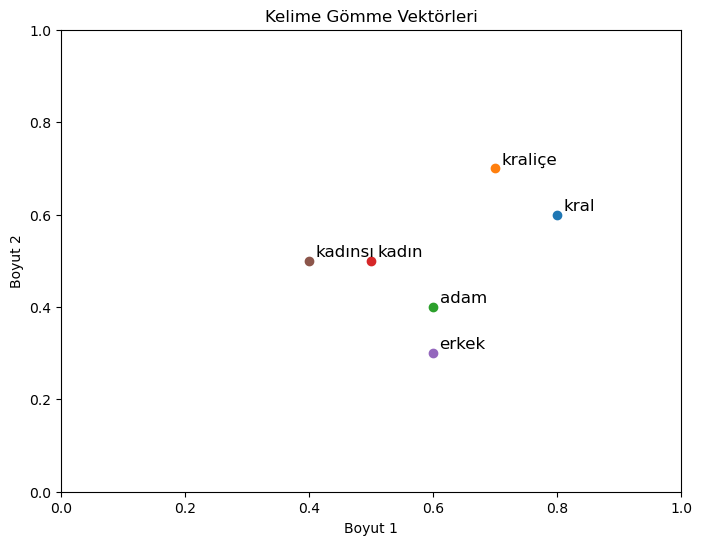

In [3]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Kelimeleri ve onların 2D vektör temsillerini tanımlayalım
words = ["kral", "kraliçe", "adam", "kadın", "erkek", "kadınsı"]
embeddings = {
    "kral": torch.tensor([0.8, 0.6]),
    "kraliçe": torch.tensor([0.7, 0.7]),
    "adam": torch.tensor([0.6, 0.4]),
    "kadın": torch.tensor([0.5, 0.5]),
    "erkek": torch.tensor([0.6, 0.3]),
    "kadınsı": torch.tensor([0.4, 0.5]),
}

# Kelime gömmelerini görselleştirelim
plt.figure(figsize=(8, 6))
for word, vector in embeddings.items():

    plt.scatter(vector[0], vector[1])
    plt.text(vector[0]+0.01, vector[1]+0.01, word, fontsize=12)
plt.title("Kelime Gömme Vektörleri")
plt.xlabel("Boyut 1")
plt.ylabel("Boyut 2")
plt.grid(False)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()

Burada kelime gömmelerini oluşturmak için Word2Vec algoritmalarını kullanabiliriz ancak genellikle LLM modelleri kendi kelime gömmelerini eğitim sırasında öğrenirler. Yani LLM modelleri, kelimeleri vektörlere dönüştürmeyi de öğrenirler. Ne yazık ki 3 boyut dışındaki vektörleri görselleştirmek mümkün olmadığı için, biz sadece bu boyutta görselleştirme yapabiliyoruz. Örneğin GPT-2 modeli 768 boyutlu kelime gömmeleri, GPT-3 modeli ise 12288 boyutlu kelime gömmeleri kullanır. 

## Tokenization(Tokenleştirme)

Tokenization, metin verisini daha küçük parçalara ayırma işlemidir. Bu parçalar token olarak adlandırılır. Tokenler kelimeler, alt kelimeler veya karakterler olabilir. Örneğin "Merhaba dünya" cümlesi iki kelime tokenine ayrılabilir: "Merhaba" ve "dünya". Ancak bazı durumlarda alt kelimeler veya karakterler token olarak kullanılabilir. Örneğin "unhappiness" kelimesi "un", "happi" ve "ness" alt kelimelerine ayrılabilir. Aşağıdaki görselde örnek bir tokenleştirme işlemi gösterilmiştir.

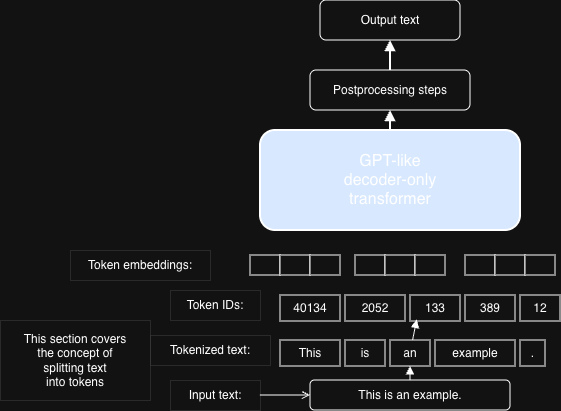

Burada LLM Verdict modeli için bir tokenleştirme işlemi gösterelim. Wikisource veri setinden bir metin alalım ve bunu tokenlere ayıralım. Bunun için https://en.wikisource.org/wiki/The_Verdict adresindeki metni kullanacağız. Oradaki metni aldım ve the_verdict.txt dosyasına kaydettim. Şimdi bu metni okuyalım ve tokenlere ayıralım.

Bu metni ayrıca https://github.com/rasbt/LLMs-from-scratch/tree/main/ch02/01_main-chapter-code adresinden de alabililirsiniz

In [5]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()
print("Karakter Sayısı:", len(raw_text))
print(raw_text[:99])

Karakter Sayısı: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


Şimdi bu 20479 karakterlik metni kelimelere ayıralım. Bunun için boşluk karakterini kullanacağız. Yani boşluk karakterine göre metni böleceğiz. Bu işlem için Python'un split() fonksiyonunu kullanabiliriz. Şimdi bu işlemi yapalım.

In [8]:
import re
text = "Merhaba, şimdi bir deneme yapalım."
result = re.split(r'(\s)', text)
print(result)

['Merhaba,', ' ', 'şimdi', ' ', 'bir', ' ', 'deneme', ' ', 'yapalım.']


In [9]:
# Bu boşlukların veya noktalama işaretlerinin kelime listesinde yer almasını istemiyoruz. Bu yüzden bu karakterleri filtreleyelim.
import re
words = re.split(r'(\s+|[.,!?;])', text)
# Boşluk ve noktalama işaretlerini filtreleyelim
words = [word for word in words if word.strip() and not re.match(r'(\s+|[.,!?;])', word)]
print("Kelime Sayısı:", len(words))
print(words[:20])

Kelime Sayısı: 5
['Merhaba', 'şimdi', 'bir', 'deneme', 'yapalım']


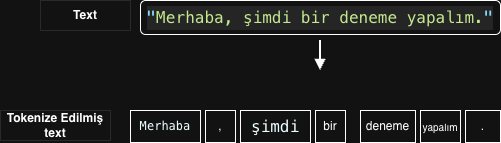

Aynı işlemi raw_text değişkeni üzerinde yapalım ve kelimelere ayıralım.

In [10]:
preprocessed = re.split(r'([,.?_!"()\']|--|\s)', raw_text)
preprocessed = [item.strip() for item in preprocessed if item.strip()]
print(len(preprocessed))

4649


In [11]:
# ilk 20 kelimeyi göster
print(preprocessed[:20])

['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was']


## Token ları Token ID lere Dönüştürme

Tokenleri sayısal verilere dönüştürmek için token ID ler kullanılır. Token ID ler, tokenlerin benzersiz sayısal temsilidir. Örneğin "Merhaba" kelimesi token ID 1 ile temsil edilebilir, "dünya" kelimesi ise token ID 2 ile temsil edilebilir. Token ID ler genellikle bir sözlükte saklanır. Bu sözlük, tokenleri token ID lere ve token ID leri tokenlere eşler. 

Az önce tokenleştirdiğimiz metni token ID lere dönüştürelim. Bunun için önce token ID sözlüğünü oluşturalım. Daha sonra tokenleri token ID lere dönüştürelim.

In [12]:
all_words = set(list(preprocessed))
vocab_size = len(all_words)
print("Kelime Dağarcığı Boyutu:", vocab_size)

Kelime Dağarcığı Boyutu: 1159


Şimdi 1159 olan dağarcık boyutunun gösterim amacıyla ilk 20 tokenini ve bunların token ID lerini gösterelim.

In [16]:
vocab = {token:integer for integer,token in enumerate(all_words)}
for i, (token, integer) in enumerate(vocab.items()):
    if i < 20:
        print(f"Token: {token} \t Token ID: {integer}")

Token: full 	 Token ID: 0
Token: nervous 	 Token ID: 1
Token: pink 	 Token ID: 2
Token: let 	 Token ID: 3
Token: near 	 Token ID: 4
Token: are 	 Token ID: 5
Token: villa 	 Token ID: 6
Token: tried 	 Token ID: 7
Token: fell 	 Token ID: 8
Token: Gisburns 	 Token ID: 9
Token: man 	 Token ID: 10
Token: moved 	 Token ID: 11
Token: lies 	 Token ID: 12
Token: platitudes 	 Token ID: 13
Token: how 	 Token ID: 14
Token: swelling 	 Token ID: 15
Token: pastels 	 Token ID: 16
Token: mirrors 	 Token ID: 17
Token: amazement 	 Token ID: 18
Token: suspected 	 Token ID: 19


Görüldüğü gibi tokenler ve token ID ler eşleştirildi. Bu eşleştirme sayesinde metin verisi sayısal verilere dönüştürülmüş oldu. Bu sayısal veriler daha sonra LLM modellerine beslenebilir. Aşağıdaki figürde tokenlerin token ID lere dönüştürülmesi gösterilmiştir.

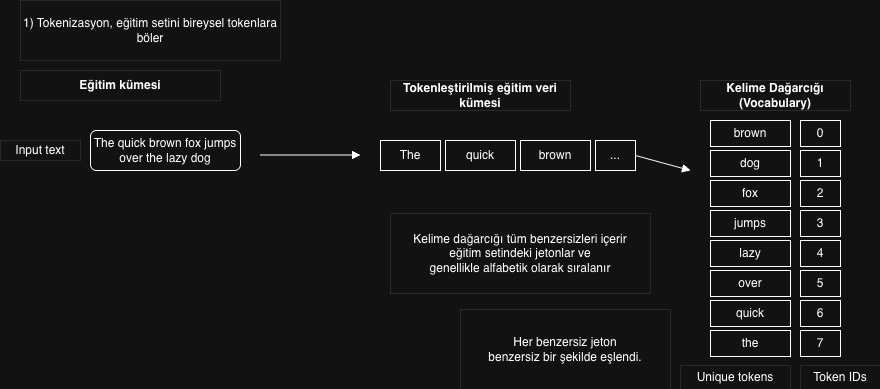

Token ID lerin sayısal verilere dönüştürülmesi sayesinde LLM modelleri metin verisini anlayabilir ve işleyebilir. Bu ID lere ulaşarak artık tekrar kelimelere dönebiliriz. şimdi bir sınıf kurarak tokenleştirme ve token ID dönüşüm işlemlerini yapalım. Yani encode ve decode işlemlerini yapalım.

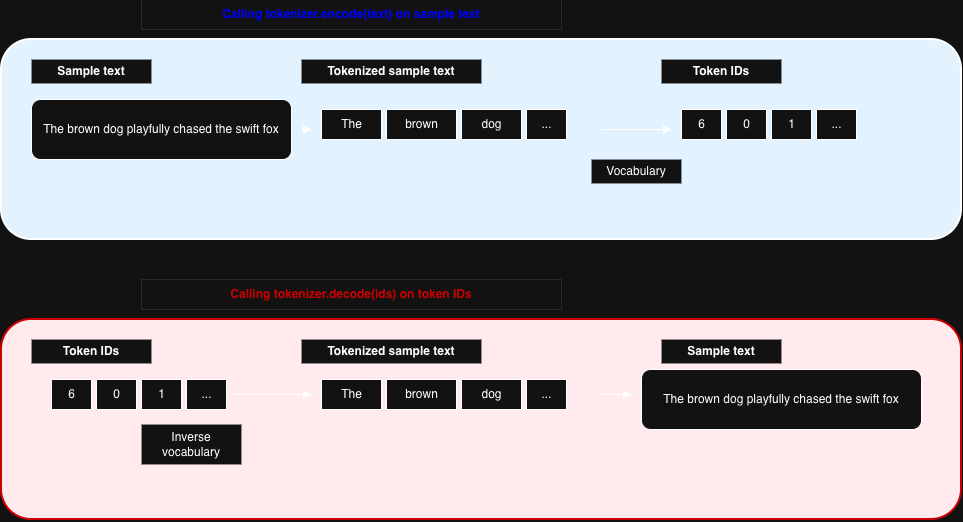

In [23]:
class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab #A
        self.int_to_str = {i:s for s,i in vocab.items()} #B
    def encode(self, text):
        preprocessed = re.split(r'([,.?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip() != ""]
        ids = [
            self.str_to_int[s] if s in self.str_to_int else self.str_to_int["<UNK>"]
            for s in preprocessed
        ]
        return ids
    def decode(self, ids): #D
        text = ' '.join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?_!"()\'])', r'\1', text) #E
        return text


Bu basit tokenizer sınıfı, metni tokenlere ayırmak ve tokenleri token ID lere dönüştürmek için kullanılabilir. Ayrıca token ID lerden tekrar tokenlere dönüştürme işlemi de yapılabilir. Şimdi bu sınıfı kullanarak metni tokenlere ayıralım ve token ID lere dönüştürelim.

In [25]:
tokenizer = SimpleTokenizerV1(vocab)
sample_text = "It's the last he painted, you know,"
ids = tokenizer.encode(sample_text)
print("Token ID ler:", ids)

Token ID ler: [105, 822, 658, 947, 790, 420, 905, 50, 251, 812, 50]


In [26]:
# Decode işlemi
print("Decoded Metin:", tokenizer.decode(ids))

Decoded Metin: It' s the last he painted, you know,


Görüldüğü gibi tokenler ve token ID ler eşleştirildi. Bu eşleştirme sayesinde metin verisi sayısal verilere dönüştürülmüş oldu. Ama yeni bir kelime olsaydı diye deneyelim.

In [27]:
text = "Hello do you like machine learning?"
tokenizer.encode(text)

KeyError: '<UNK>'

Buradaki problem daha önce sözlükte olmayan bir kelime ile karşılaştığımızda ortaya çıkıyor. Bu durumda tokenizer bu kelimeyi tanıyamıyor ve hata veriyor. Bu yüzden daha gelişmiş tokenleştirme yöntemlerine ihtiyacımız var. Bu yöntemlerden biri Byte Pair Encoding(BPE) yöntemidir. BPE, metni alt kelimelere ayırarak daha esnek bir tokenleştirme sağlar. 

## Byte Pair Encoding (BPE)

Byte Pair Encoding (BPE), metin verisini daha küçük parçalara ayırmak için kullanılan bir tokenleştirme yöntemidir. BPE, sıkça birlikte görülen karakter çiftlerini birleştirerek yeni tokenler oluşturur. Bu sayede daha esnek ve verimli bir tokenleştirme sağlar. BPE, özellikle nadir kelimeleri ve yeni kelimeleri temsil etmek için etkilidir. Çünkü nadir kelimeler genellikle alt kelimelerden oluşur ve BPE bu alt kelimeleri yakalayabilir. BPE, LLM modellerinde yaygın olarak kullanılır. Örneğin GPT-2 ve GPT-3 modelleri BPE tokenleştirme yöntemini kullanır. 

BPE yi kodlamak zor olduğundan biz tiktoken kütüphanesini kullanacağız. Bu kütüphane BPE tokenleştirme yöntemini uygular ve kolayca kullanılabilir. Yüklemek için aşağıdaki komutu kullanabilirsiniz:

```bash
pip install tiktoken
```

In [28]:
import tiktoken
tiktoken.__version__

'0.12.0'

yükleme tamamlandıktan sonra tiktoken kütüphanesini kullanarak metni tokenlere ayıralım ve token ID lere dönüştürelim.


In [30]:
tokenizer = tiktoken.get_encoding("gpt2")
sample_text = "It's the last he painted, you know,"
ids = tokenizer.encode(sample_text)
print("Token ID ler:", ids)
print("Decoded Metin:", tokenizer.decode(ids))


Token ID ler: [1026, 338, 262, 938, 339, 13055, 11, 345, 760, 11]
Decoded Metin: It's the last he painted, you know,


In [33]:
tokenizer.n_vocab

50257

In [37]:
text = "Hello world"
ids = tokenizer.encode(text)
print("Normal encode:", ids)

# Özel token ekleyelim
ids_with_eot = tokenizer.encode(
    text + "<|endoftext|>",
    allowed_special={"<|endoftext|>"}
)

print("EOT ile encode:", ids_with_eot)
print("Decoded:", tokenizer.decode(ids_with_eot))

Normal encode: [15496, 995]
EOT ile encode: [15496, 995, 50256]
Decoded: Hello world<|endoftext|>


endoftext burada çok yüksek bir token ID ye sahip. Çünkü bu token, metin sonunu temsil ediyor ve modelin metin sonunu anlaması için önemli. Bu yüzden yüksek bir ID verilmiş. gpt2 tokenizer 50257 token içeren bir dağarcığa sahip. Yani 0 dan 50256 ya kadar token ID ler var. endoftext tokeni ise 50256 ID sine sahip. yani son token. Bu token, modelin metin sonunu anlaması için kullanılır. 

In [38]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

sample_text = "The process is electrohypermegacortexification."

ids = tokenizer.encode(sample_text)
print("Token ID'ler:", ids)

decoded = tokenizer.decode(ids)
print("Decoded Metin:", decoded)

Token ID'ler: [464, 1429, 318, 15206, 49229, 28917, 330, 26158, 2649, 13]
Decoded Metin: The process is electrohypermegacortexification.


BPE bilinmeyen bir kelime ile karşılaştığında, bu kelimeyi alt kelimelere ayırır ve bu alt kelimeleri token ID lere dönüştürür. Bu sayede yeni kelimeler de temsil edilebilir. Örneğin "electrohypermegacortexification" kelimesi BPE ile electro | hyper | mega | cortex | ification alt kelimelerine ayrılabilir ve bu alt kelimeler token ID lere dönüştürülebilir.

## Kaydırma Penceresi Yaklaşımıyla Eğitim Örnekleri Örnekleme

Kaydırma penceresi yaklaşımı, metin verisinden eğitim örnekleri oluşturmak için kullanılan bir yöntemdir. Bu yöntemde, metin verisi üzerinde kaydırılabilir bir pencere kullanılır ve bu pencere içindeki tokenler eğitim örnekleri olarak seçilir. Pencere belirli bir boyutta olabilir ve her adımda belirli bir sayıda token kaydırılır. Bu sayede metin verisi üzerinde birçok eğitim örneği oluşturulabilir.

Bu yöntem ile metin girdi-çıktı ikilisine dönüştürülür. Örneğin, pencere boyutu 5 ve kaydırma adımı 1 ise, metin verisi üzerinde kaydırma penceresi kullanılarak aşağıdaki gibi eğitim örnekleri oluşturulabilir:

| Girdi Tokenleri       | Çıktı Tokeni |
|----------------------|--------------|
| token1, token2, token3, token4, token5 | token6 |
| token2, token3, token4, token5, token6 | token7 |
| token3, token4, token5, token6, token7 | token8 |

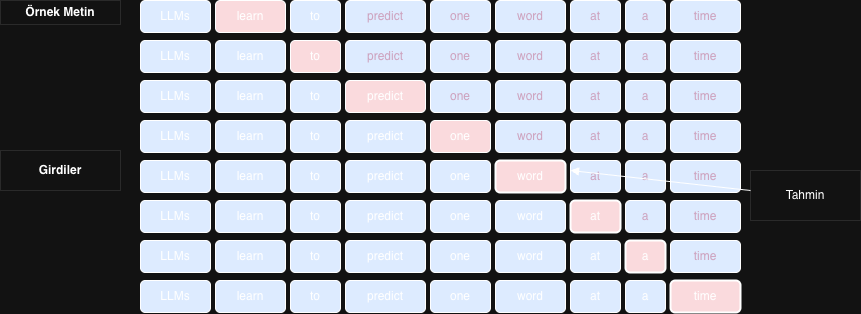

Şimdi bu yöntemi kullanarak metin verisinden eğitim örnekleri oluşturalım. Bunun için önce metni tokenlere ayıralım ve token ID lere dönüştürelim. Daha sonra kaydırma penceresi yaklaşımını kullanarak eğitim örnekleri oluşturalım.

In [39]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

enc_text = tokenizer.encode(raw_text)
print("Toplam Token Sayısı:", len(enc_text))

Toplam Token Sayısı: 5145


In [40]:
# 50 tokenı eğitim amacıyla ayıralım
enc_sample = enc_text[50:]

Girdi ve çıktı çiftlerine ayırarak bir sonraki hedefi tahmin etmeye çalışacağız. Bunun için en kolayı x ve y dizilerini oluşturmak. x dizisi girdiler, y dizisi ise çıktılar olacak. Bunu yaparken de kaydırma penceresi yaklaşımını kullanacağız. Şimdi bunu kodlayalım.

In [42]:
context_size = 4
x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]
print(f"x: {x}")
print(f"y: {y}")   

x: [290, 4920, 2241, 287]
y: [4920, 2241, 287, 257]


Her seferinde pencereyi bir token kaydırarak x ve y dizilerini oluşturduk. Şimdi bu işlemi tüm metin verisi için yapalım ve eğitim örnekleri oluşturalım.

In [43]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    print(context, "---->", desired)

[290] ----> 4920
[290, 4920] ----> 2241
[290, 4920, 2241] ----> 287
[290, 4920, 2241, 287] ----> 257


----> dan önceki tüm tokenler girdi, ----> dan sonraki token ise çıktı olacak şekilde eğitim örnekleri oluşturduk. Bu sayede metin verisinden birçok eğitim örneği elde ettik. 

Şimdi gösterim amaçlı olarak token ID lerini kullandık. Ancak gerçek uygulamalarda bu token ID ler, kelime gömmeleri(vectors) ile temsil edilir. 

In [45]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    print(tokenizer.decode(context), "---->", tokenizer.decode([desired]))

 and ---->  established
 and established ---->  himself
 and established himself ---->  in
 and established himself in ---->  a


Bir girdi-çıktı örneği oluşturduk. Şimdi tokenlerin embeddinglere dönüşmesi için bir adım kaldı. Daha önce konuştuğumuz gibi bu işlem için verimli bir veri yükleyicisi (data loader) kullanabiliriz. Pytorch tensorları ile bu işlemi yapabiliriz. input veri setlerini alacak ve hedef tensorları oluşturacak bir veri yükleyici yazabiliriz. 

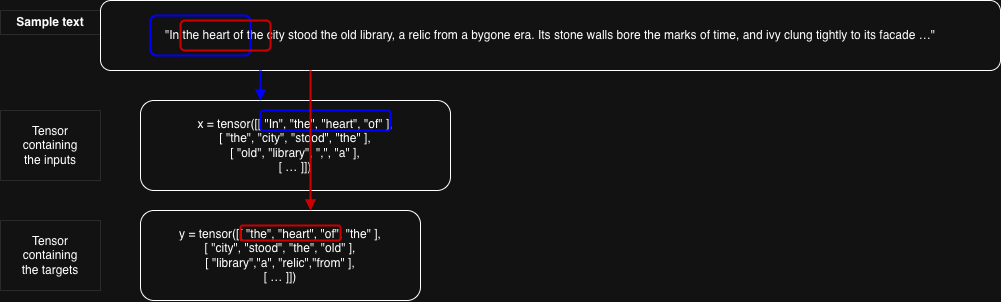


Şekilde, gösterim amaçlı olarak tokenleri dize formatında göstermektedir, ancak kod uygulaması token ID leri üzerinde doğrudan çalışacaktır çünkü BPE tokenizer ın encode metodu hem tokenleştirme hem de token ID lere dönüştürmeyi tek bir adımda gerçekleştirir. Verimli bir veri yükleyici uygulaması için PyTorch'un yerleşik dataset ve DataLoader sınıflarını kullanacağız.

In [47]:
import torch
from torch.utils.data import Dataset, DataLoader
class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.tokenizer = tokenizer
        self.input_ids = []
        self.target_ids = []
        token_ids = tokenizer.encode(txt) #A
        for i in range(0, len(token_ids) - max_length, stride): #B
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))
    def __len__(self): #C
        return len(self.input_ids)
    def __getitem__(self, idx): #D
        return self.input_ids[idx], self.target_ids[idx]

GPTDatasetV1, PyTorch’un Dataset sınıfını temel alarak, büyük bir metin veri kümesinden modele uygun eğitim örnekleri üretmek için kullanılır. Bu sınıf, metni önce token ID’lerine dönüştürür, ardından her biri max_length kadar token içeren sabit uzunlukta parçalara ayırır ve bu parçaları input_chunk olarak modele sunar. Aynı zamanda, her bir girdi parçası için modelin tahmin etmesi gereken hedef diziyi (target_chunk) üretir; bu hedef dizi genellikle girdinin bir token kaydırılmış hâlidir ve modelin “bir sonraki token” tahmini yapmasını sağlar. Dataset sınıfı, veri kümesinden tek bir örnek istendiğinde ne döndürüleceğini tanımlarken, PyTorch DataLoader bu tekil örnekleri otomatik olarak mini-batch’ler hâlinde gruplayarak eğitim sürecinde verinin daha verimli, düzenli ve ölçeklenebilir bir biçimde kullanılmasını sağlar.

In [60]:
import tiktoken
from torch.utils.data import DataLoader

def create_dataloader_v1(
    txt,
    batch_size=4,
    max_length=256,
    stride=128,
    shuffle=True,
    drop_last=True
):
    tokenizer = tiktoken.get_encoding("gpt2")  # A
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)  # B

    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last
    )
    return dataloader


# --- Veri okuma ---
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

# --- DataLoader oluşturma ---
dataloader = create_dataloader_v1(
    raw_text,
    batch_size=1,
    max_length=4,
    stride=1,
    shuffle=False
)

# --- Batch'leri alma ---
data_iter = iter(dataloader)  # A
first_batch = next(data_iter)
print("First batch:", first_batch)

second_batch = next(data_iter)
print("Second batch:", second_batch)

First batch: [tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]
Second batch: [tensor([[ 367, 2885, 1464, 1807]]), tensor([[2885, 1464, 1807, 3619]])]


İki batch kıyaslandığında birbirinin takibi olduğu görülüyor. Bu da veri yükleyicisinin doğru çalıştığını gösteriyor. max_length parametresi ile belirlenen pencere boyutu kadar token içeren girdiler ve bu girdilere karşılık gelen çıktılar doğru şekilde oluşturulmuş. stride parametresi ise kaydırma adımını belirliyor. batch_size parametresi ise her batchte kaç örnek olacağını belirliyor. shuffle parametresi ise verilerin karıştırılıp karıştırılmayacağını belirliyor. drop_last parametresi ise son batchin tam dolu olmaması durumunda atılıp atılmayacağını belirliyor.

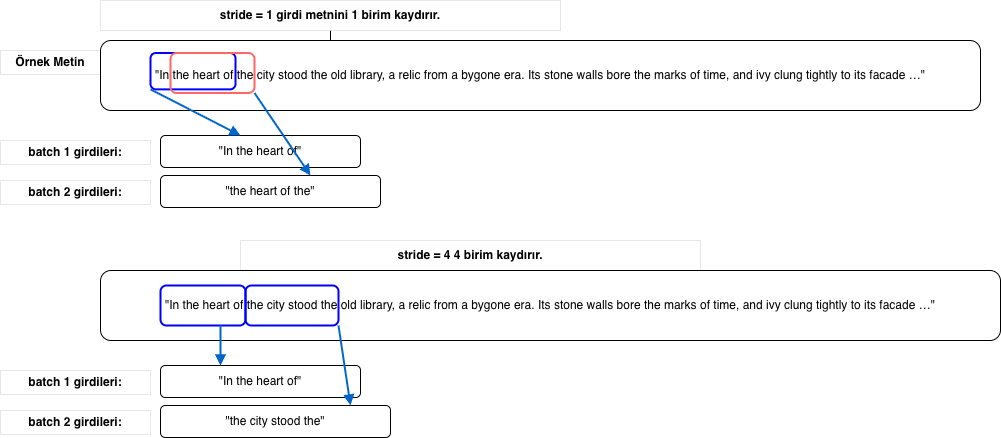

Batch size ı biraz daha yüksek alalım ve tekrar bakalım.

In [62]:
dataloader = create_dataloader_v1(
    raw_text,
    batch_size=8,
    max_length=4,
    stride=4,
    shuffle=False
)

data_iter = iter(dataloader)
inputs, targets = next(data_iter)

print("Inputs:\n", inputs)
print("\nTargets:\n", targets)

Inputs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Targets:
 tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])


**Kodun Adım Adım Açıklaması**
- create_dataloader_v1(...): Ham metin (raw_text) girdi olarak verilir.
- batch_size=8: Aynı anda 8 bağımsız eğitim örneği üretilir.
- max_length=4: Her örnek 4 token uzunluğundadır.
- stride=4: Token penceresi her örnekten sonra 4 token kaydırılır.
- shuffle=False: Örnekler metindeki doğal sırayla alınır (didaktik amaçla - ih edilir).
- data_iter = iter(dataloader)
- DataLoader, Python iterator’ına dönüştürülür.
- Bu iterator, her çağrıda bir mini-batch döndürür.
- inputs, targets = next(data_iter)
- İlk batch alınır.
- inputs: (8, 4) boyutunda giriş tensörü.
- targets: (8, 4) boyutunda hedef tensörü.



Inputs (girdiler):

tensor([[ 40,  367, 2885, 1464],
        [1807, 3619,  402,  271],
        ...
        [ 284, 3285,  326,   11]])

- Her satır, bağımsız bir eğitim örneğidir.
- Her satırdaki 4 sayı, GPT-2 tokenizer tarafından üretilmiş token ID’leridir.
- Model bu diziyi girdi olarak alır.

**Çıktı Tensörlerinin Anlamı**

Targets (hedefler):

tensor([[ 367, 2885, 1464, 1807],
        [3619,  402,  271, 10899],
        ...
        [3285,  326,   11,   287]])

- targets, inputs’un bir token sola kaydırılmış hâlidir.
- Matematiksel olarak her batch için ilişki şu şekildedir:

$$\text{target}_{i,j} = \text{input}_{i,j+1}$$
- Son sütundaki hedef token, metindeki bir sonraki gerçek token’dan alınır.


Eğitim Perspektifi (Önemli Nokta)
- Batch size > 1 olduğunda:
- Hesaplama paralelleşir.
- GPU/TPU kullanımı daha verimli olur.
- Ancak her satır hâlâ bağımsız bir bağlam penceresidir; satırlar arasında bilgi paylaşımı yoktur.


## Kelime Gömmelerini Oluşturma (Token Embeddings)

Son iki adımda girdi metinlerini LLM eğitimi için token ID lere dönüştürdük. Ancak LLM modelleri token ID lerle değil, kelime gömmeleri(vectors) ile çalışır. Bu yüzden token ID leri kelime gömmelerine dönüştürmemiz gerekiyor. Bu işlem için bir embedding katmanı kullanabiliriz. Embedding katmanı, token ID leri alır ve bunları kelime gömmelerine dönüştürür. Bu kelime gömmeleri daha sonra LLM modeline beslenir.

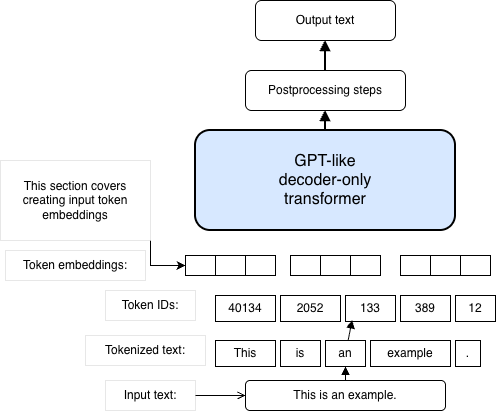

Token ID lerin kelime gömmelerine dönüştürülmesi için her token için ağırlıklandırılmış bir vektör matrisi başlangıçta rastgele olarak oluşturulur. Eğitim sırasında bu vektörler, modelin öğrenme süreciyle birlikte güncellenir ve optimize edilir. İleride bu konuyu daha detaylı inceleyeceğiz.

Kelime gömmeleri veya embeddingler, kelimelerin veya tokenlerin sayısal vektörler olarak temsil edilmesidir. Şimdi token ID lerin kelime gömmelerine dönüştürülmesini gösteren bir kod parçası ekleyelim.

In [63]:
input_ids = torch.tensor([2, 3, 5, 1])

Şimdilik çok kısa bir örnekle başlayalım. Örneğin elimizde 6 kelimelik bir dağarcık olsun. Önceki örnekte BPE tokenizer da bu sayı 50257 idi. Şimdi bu 6 kelimelik dağarcık için 3 boyutlu kelime gömmeleri oluşturalım ve token ID lerini bu gömmelere dönüştürelim.

In [85]:
vocab_size = 6  # Dağarcık boyutu
output_dim = 3  # Kelime gömme boyutu

vocab_size ve output_dim parametrelerini kullanarak Pytorch ta bir embedding katmanı oluşturalım. Pytorch un rassal sayı üretecini de 123 ile başlatalım ki sonuçlar tekrarlanabilir olsun.

In [86]:
torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)
print(embedding_layer.weight)

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)


Görüldüğü gibi embedding katmanındaki ağırlık matrisi çok küçük ve rassal değerlerle başlatılmış. Şimdi bazı token ID lerini bu embedding katmanına verelim ve kelime gömmelerini elde edelim. Örneğin token ID leri [0, 1, 2, 3, 4, 5] olan bir dizi oluşturalım ve bu diziyi embedding katmanına verelim.

In [87]:
print(embedding_layer(torch.tensor([3]))) # token ID lerin konumları sıfırdan başlar. 

tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


## Embedding katmanları ve matris çarpımı

One-hot encoding’e aşina olanlar için, yukarıda anlatılan embedding katmanı yaklaşımı aslında, one-hot encoding uygulanmasının ardından tam bağlı (fully connected) bir katmanda matris çarpımı yapılmasının daha verimli bir şekilde gerçekleştirilmiş hâlidir. Bu durum, GitHub’daki ek kodda şu adreste gösterilmektedir:
https://github.com/rasbt/LLMs-fromscratch/tree/main/ch02/03_bonus_embedding-vs-matmul

Embedding katmanı, one-hot encoding ve matris çarpımı yaklaşımıyla eşdeğer ancak daha verimli bir uygulama olduğu için, geri yayılım (backpropagation) ile optimize edilebilen bir sinir ağı katmanı olarak düşünülebilir.

Daha önce, tek bir token ID’sinin üç boyutlu bir embedding vektörüne nasıl dönüştürüldüğünü görmüştük. Şimdi bunu, daha önce tanımladığımız dört giriş ID’sinin tamamına uyguladık.
şimdi aşağıdaki kodu çalıştıralım:

```python
(torch.tensor([2, 3, 5, 1])):

print(embedding_layer(input_ids))
```

Çıktı, bunun 4×3 boyutunda bir matris ürettiğini göstermektedir:

```python
tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)
```

Bu çıktı matrisindeki her bir satır, embedding ağırlık matrisinden yapılan bir lookup (indeksleme) işlemi ile elde edilir.

Embedding layer = one-hot encoding + matris çarpımının hızlı ve pratik hâli

Adım adım düşünelim

**One-hot encoding neden pahalı?**
- Diyelim ki kelime dağarcığınızda (vocabulary) 50.000 kelime var.
- Her kelimeyi 50.000 boyutlu bir vektörle (one-hot) temsil etmek:
- Bellek açısından verimsiz
- Hesaplama açısından gereksiz yere maliyetlidir

Örnek:

kelime_id = 3
one-hot = [0, 0, 0, 1, 0, 0, ..., 0]  (50.000 boyut)


**Matris çarpımı aslında ne yapıyor?**

- One-hot vektörü embedding ağırlık matrisiyle çarptığınızda:
- Sadece ilgili satır seçilmiş olur
- Yani matematiksel olarak:

$$\text{one-hot}{i}^\top , W = W{i,:}$$

Embedding layer şunu der:

"Madem sonuçta sadece ilgili satırı alıyoruz, neden dev bir one-hot vektörü oluşturalım?"

Bunun yerine doğrudan:
- Token ID’yi alır
- Ağırlık matrisinden ilgili satırı lookup yapar

Bu yüzden:
- Daha hızlı
- Daha az bellek kullanır
- Aynı matematiksel sonucu üretir

Verilen örneği yorumlayalım

input_ids = [2, 3, 5, 1]

Embedding layer çıktısı:
- 4 satır → 4 token
- 3 sütun → embedding boyutu = 3

[token 2] → [ 1.2753, -0.2010, -0.1606]

[token 3] → [-0.4015,  0.9666, -1.1481]

[token 5] → [-2.8400, -0.7849, -1.4096]

[token 1] → [ 0.9178,  1.5810,  1.3010]

Her satır şunu temsil eder:

“Bu token’ın öğrenilmiş sayısal anlamı”

Neden öğrenilebilir?
- Embedding matrisi bir parametre setidir
- Geri yayılım ile:
- Hatalar embedding ağırlıklarına ulaşır
- Token temsilcileri görev özelinde optimize edilir

Bu yüzden embedding layer:
- Sadece bir lookup tablosu değil
- Öğrenilebilir bir sinir ağı katmanıdır

## Konumsal Embeddingler (Positional Embeddings)

Token’ın mutlak konumuna odaklanmak yerine, göreli konumsal embedding’ler token’lar arasındaki göreli konum veya mesafeye odaklanır. Bu, modelin “hangi tam konumda” yerine “birbirlerinden ne kadar uzakta” oldukları üzerinden ilişkileri öğrenmesi anlamına gelir. Bunun avantajı, modelin eğitim sırasında görmediği uzunluklardaki dizilere bile daha iyi genelleme yapabilmesidir.

Her iki konumsal embedding türü de LLM’lerin token’lar arasındaki sıra ve ilişkileri daha iyi anlamasını hedefler; böylece daha doğru ve bağlama duyarlı tahminler yapılmasını sağlar. Hangi yaklaşımın seçileceği, çoğu zaman uygulamaya ve işlenen verinin doğasına bağlıdır.

OpenAI’nin GPT modelleri, orijinal Transformer modelindeki gibi sabit (önceden tanımlı) positional encoding’ler yerine, eğitim sırasında optimize edilen mutlak positional embedding’ler kullanır. Bu optimizasyon süreci, model eğitiminin bir parçasıdır ve bu kitapta ilerleyen bölümlerde uygulanacaktır. Şimdilik, gelecek bölümlerde LLM girdilerini oluşturmak için başlangıç konumsal embedding’lerini oluşturalım.

Bu bölümde örnekleme amacıyla çok küçük embedding boyutları kullanmıştık. Şimdi daha gerçekçi ve kullanışlı bir boyuta geçiyoruz ve giriş token’larını 256 boyutlu vektörler olarak kodluyoruz. Bu değer, GPT-3’ün kullandığı embedding boyutundan (12.288) küçüktür ancak deneysel çalışmalar için makuldür. Ayrıca token ID’lerinin, daha önce uyguladığımız ve kelime dağarcığı 50.257 olan BPE tokenizer tarafından üretildiğini varsayıyoruz:


In [80]:
output_dim = 256
vocab_size = 50257
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

Yukarıdaki token_embedding_layer kullanıldığında, veri yükleyiciden (data loader) örnek alındığında, her batch içindeki her token 256 boyutlu bir vektöre dönüştürülür. Batch boyutu 8 ve her örnekte 4 token varsa, sonuç 8 × 4 × 256 boyutlu bir tensör olur.

Önce, 2.6 bölümündeki “sliding window ile veri örnekleme” kısmından data loader’ı oluşturalım:


In [81]:
max_length = 4
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length, stride=max_length, shuffle=True)

data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Token IDs:\n", inputs)
print("\nInputs shape:\n", inputs.shape)

Token IDs:
 tensor([[  314,  1053,   442, 17758],
        [  510,   465, 12036,    13],
        [24818,   417,    12, 12239],
        [  373,   465,   898, 41793],
        [21213,    11,   314,  3947],
        [ 2106,  1701,   198,   198],
        [  520,  5493,  1231,  1592],
        [  679,  1422,   470, 10505]])

Inputs shape:
 torch.Size([8, 4])


Görüldüğü gibi token ID tensörü 8×4 boyutludur; yani batch, her biri 4 token içeren 8 metin örneğinden oluşmaktadır.

Şimdi embedding katmanını kullanarak bu token ID’leri 256 boyutlu vektörlere dönüştürelim:



In [82]:
token_embeddings = token_embedding_layer(inputs)
print(token_embeddings.shape)

torch.Size([8, 4, 256])


Bu da her token ID’nin artık 256 boyutlu bir vektörle temsil edildiğini gösterir.

GPT modelinin mutlak positional embedding yaklaşımı için, token embedding katmanıyla aynı boyutta ikinci bir embedding katmanı oluştururuz:



In [83]:
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)
pos_embeddings = pos_embedding_layer(torch.arange(context_length))
print(pos_embeddings.shape)

torch.Size([4, 256])


Burada pos_embeddings’e verilen giriş genellikle torch.arange(context_length) şeklinde, 0’dan maksimum uzunluk − 1’e kadar giden bir indeks vektörüdür. context_length, LLM’in desteklediği maksimum giriş uzunluğunu ifade eder. Pratikte, metin bu uzunluğu aşarsa kırpma (truncation) yapılır.

Yani her pozisyon için 256 boyutlu bir konumsal vektör vardır. Artık bu vektörleri doğrudan token embedding’lere ekleyebiliriz. PyTorch, 4×256 boyutlu pos_embeddings tensörünü, her batch’teki 4×256 boyutlu token embedding’lere otomatik olarak ekler:

Elde edilen input_embeddings, artık 3. bölümde uygulanacak olan ana LLM katmanlarına girdi olarak verilebilecek embedding’lerdir.

Ana fikir (tek cümle): Model ya “tam olarak neredeyim?”i bilir (absolute), ya da “diğerlerine göre ne kadar uzaktayım?”ı bilir (relative).

**Relative positional embedding sezgisi**
Önemli olan:
- “Bu kelime 7. sırada mı?” değil
- “Bu kelime diğerinden 2 token sonra mı geliyor?”
Avantaj:
- Farklı uzunluktaki metinlerde daha iyi genelleme
- Uzunluğu değişen dizilerde daha esnek davranış

**Absolute positional embedding sezgisi**
- Her pozisyonun kimliği vardır:
- 	0.	pozisyon → ayrı vektör
- 	1.	pozisyon → ayrı vektör
GPT ailesi bu yaklaşımı kullanır
Bu vektörler:
- Sabit değil
- Eğitim sırasında öğrenilir

**GPT giriş embedding’i nasıl oluşur?**

Her token için:

$$\text{InputEmbedding} = \text{TokenEmbedding} + \text{PositionalEmbedding}$$
- Token embedding → anlam
- Positional embedding → sıra
- Toplam → bağlamlı temsil

**Boyutlar neden önemli?**
- Batch = 8
- Sekans uzunluğu = 4
- Embedding boyutu = 256

Sonuç tensörü:
- 8 × 4 × 256
- LLM artık:
- Her token’ın
- Hem anlamını
- Hem konumunu
bilir

⸻

## Özet
- LLM’ler ham metinle çalışamaz; metin önce embedding’lere dönüştürülür.
- Metin → token → token ID → embedding vektörü hattı izlenir.
- Özel token’lar (<|unk|>, <|endoftext|>) bağlam yönetimini kolaylaştırır.
- BPE tokenizer, bilinmeyen kelimeleri alt parçalara bölerek etkili çalışır.
- Sliding window yöntemiyle eğitim için giriş–hedef çiftleri üretilir.
- PyTorch embedding katmanları, token ID → vektör eşlemesini lookup ile yapar.
- Token embedding’ler konum bilgisi içermez.
- Bu eksiklik:
- Absolute veya
- Relative positional embedding
ile giderilir.
- GPT modelleri, öğrenilebilir mutlak positional embedding’leri, token embedding’lere ekleyerek kullanır.